# Ligue 1 match outcome prediction

Predict home win (1), draw (0) or away win (-1) for 233 fixtures in the supplied 2025–26 file. This is a retrospective experiment using the supplied historical archive, not live forecasts. The evaluation uses a **fixed pre-season information cutoff** for each season, matching the unlabeled target file. No observed results from the target season are used.

In [15]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, ConfusionMatrixDisplay

archive = Path('Foot.zip')
if not archive.exists():
    archive = Path('../Foot.zip')
with zipfile.ZipFile(archive) as z:
    tables = {Path(name).stem: pd.read_csv(z.open(name), low_memory=False) for name in z.namelist() if name.endswith('.csv')}
for name, df in tables.items():
    tables[name] = df.loc[:, ~df.columns.str.startswith('Unnamed:')].copy()
    if 'date' in df:
        tables[name]['date'] = pd.to_datetime(df['date'], errors='raise')
summary = pd.DataFrame([{'file': k, 'rows': len(v), 'columns': len(v.columns), 'missing_cells': int(v.isna().sum().sum())} for k,v in tables.items()])
summary

,file,rows,columns,missing_cells
0,clubs_fr,36,13,36
1,game_events_before2025,61944,11,88947
2,game_lineups,161049,10,0
3,matchs_2013_2024,4691,22,1132
4,match_2025,233,12,1
5,player_appearance,128240,13,0
6,player_valuation_before_season,32856,6,0
7,sample_results,233,2,0


## 1. Audit and exploration
The file name suggests 2013–2024, but the actual historical dates begin in 2012 and end in May 2025. The season field represents the starting year. Club metadata and current-club fields are not used as historical features because they may represent a later snapshot. Actual lineups, attendance and match events for target fixtures are unavailable or potentially post-match information.

Historical: (4691, 22) 2012-08-10 00:00:00 2025-05-17 00:00:00
Target: (233, 12) 2025-08-15 00:00:00 2026-03-15 00:00:00


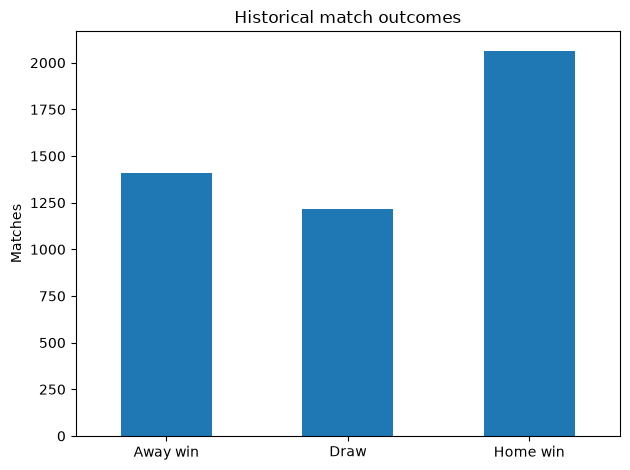

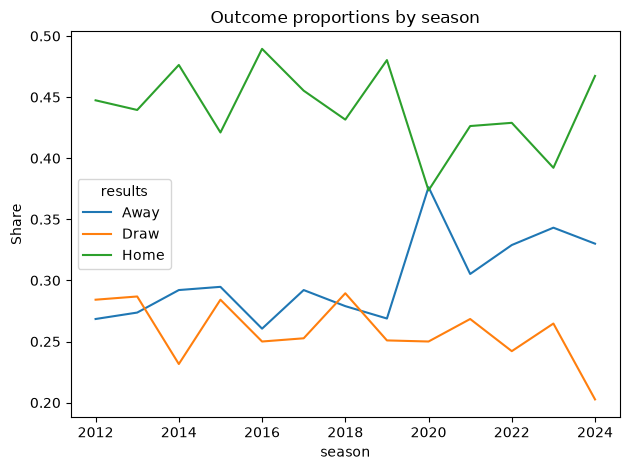

In [16]:
hist = tables['matchs_2013_2024'].sort_values(['date','game_id']).copy()
test = tables['match_2025'].sort_values(['date','game_id']).copy()
sample = tables['sample_results'].copy()
assert hist.game_id.is_unique and test.game_id.is_unique and sample.game_id.is_unique
assert set(hist.game_id).isdisjoint(test.game_id)
assert set(hist.results) == {-1,0,1}
assert (np.sign(hist.home_club_goals-hist.away_club_goals)==hist.results).all()
assert hist.date.max() < test.date.min()
assert set(sample.game_id)==set(test.game_id)
print('Historical:', hist.shape, hist.date.min(), hist.date.max())
print('Target:', test.shape, test.date.min(), test.date.max())
counts = hist.results.value_counts().reindex([-1,0,1])
counts.index = ['Away win','Draw','Home win']
counts.plot.bar(rot=0, title='Historical match outcomes', ylabel='Matches'); plt.tight_layout(); plt.show()
pd.crosstab(hist.season, hist.results, normalize='index').rename(columns={-1:'Away',0:'Draw',1:'Home'}).plot(title='Outcome proportions by season', ylabel='Share'); plt.tight_layout(); plt.show()

## 2. Historical features
One row per team and match. Player appearances and event counts are aggregated before joining to avoid duplicating matches. For each season, all features are computed from matches strictly before its first fixture. This deliberately sacrifices within-season updates to make evaluation consistent with the target file. Historical club membership is derived from appearances, not current-club fields. Player valuation and lineup tables are audited but excluded from this version: historical membership and coverage need further validation.

In [17]:
home = hist[['game_id','date','season','home_club_id','away_club_id','home_club_goals','away_club_goals','results']].copy()
home.columns = ['game_id','date','season','club','opponent','gf','ga','result']
home['home'] = 1
away = home.copy()
away[['club','opponent']] = home[['opponent','club']].to_numpy()
away[['gf','ga']] = home[['ga','gf']].to_numpy()
away['result'] = -home.result
away['home'] = 0
team = pd.concat([home,away], ignore_index=True).sort_values(['date','game_id'])
team['points'] = team.result.map({1:3,0:1,-1:0})
team['gd'] = team.gf-team.ga
app = tables['player_appearance'].drop_duplicates('appearance_id')
app_agg = app.groupby(['game_id','player_club_id']).agg(players=('player_id','nunique'), minutes=('minutes_played','sum'), assists=('assists','sum'), yellows=('yellow_cards','sum'), reds=('red_cards','sum')).reset_index().rename(columns={'player_club_id':'club'})
events = tables['game_events_before2025'].drop_duplicates('game_event_id')
event_agg = events.groupby(['game_id','club_id','type']).size().unstack(fill_value=0).reset_index().rename(columns={'club_id':'club','Cards':'event_cards','Substitutions':'event_subs','Goals':'event_goals'})
team = team.merge(app_agg,on=['game_id','club'],how='left',validate='1:1').merge(event_agg,on=['game_id','club'],how='left',validate='1:1')
assert len(team)==2*len(hist)
team.head()

,game_id,date,season,club,opponent,gf,ga,result,home,points,gd,players,minutes,assists,yellows,reds,event_cards,event_goals,event_subs
0,2229837,2012-08-10,2012,969,415,1,1,0,1,1,0,14.0,939.0,1.0,1.0,1.0,2.0,1.0,3.0
1,2229837,2012-08-10,2012,415,969,1,1,0,0,1,0,14.0,967.0,1.0,1.0,2.0,3.0,1.0,3.0
2,2229834,2012-08-11,2012,14171,40,2,3,-1,1,0,-1,14.0,990.0,1.0,3.0,0.0,3.0,2.0,3.0
3,2229834,2012-08-11,2012,40,14171,3,2,1,0,3,1,14.0,990.0,3.0,3.0,0.0,3.0,3.0,3.0
4,2229835,2012-08-11,2012,750,595,2,3,-1,1,0,-1,14.0,990.0,2.0,1.0,0.0,1.0,2.0,3.0


In [18]:
def elo_ratings(past, k=20, advantage=80):
    ratings = {}
    for r in past.sort_values(['date','game_id']).itertuples():
        h,a = r.home_club_id,r.away_club_id
        rh,ra = ratings.get(h,1500),ratings.get(a,1500)
        expected = 1/(1+10**(-(rh+advantage-ra)/400))
        actual = {1:1,0:0.5,-1:0}[r.results]
        change = k*(actual-expected)
        ratings[h],ratings[a] = rh+change,ra-change
    return ratings

def build_features(fixtures, cutoff):
    past = hist[hist.date < cutoff]
    t = team[team.date < cutoff].sort_values(['date','game_id'])
    ratings = elo_ratings(past)
    stats = {}
    for club,g in t.groupby('club'):
        s = {'elo': ratings.get(club,1500), 'history_count':len(g)}
        for w in (3,5,10):
            for c in ['points','gf','ga','gd']:
                s[f'{c}_{w}'] = g[c].tail(w).mean()
        for venue in (0,1):
            sub = g[g.home==venue].tail(10)
            for c in ['points','gf','ga']:
                s[f'{c}_venue{venue}'] = sub[c].mean()
        for c in ['players','minutes','assists','yellows','reds','event_cards','event_subs','event_goals']:
            s[c+'_10'] = g[c].tail(10).mean()
        stats[club]=s
    keys = list(next(iter(stats.values())))
    rows=[]
    for r in fixtures.itertuples():
        h,a=r.home_club_id,r.away_club_id
        hs,as_=stats.get(h,{}),stats.get(a,{})
        row={'game_id':r.game_id,'date':r.date}
        for key in keys:
            default=1500 if key=='elo' else (0 if key=='history_count' else np.nan)
            hv,av=hs.get(key,default),as_.get(key,default)
            row['h_'+key],row['a_'+key],row['diff_'+key]=hv,av,hv-av
        h2h=t[(t.club==h)&(t.opponent==a)].tail(5)
        row['h2h_points']=h2h.points.mean()
        row['h2h_count']=len(h2h)
        rows.append(row)
    return pd.DataFrame(rows)

frames=[]
for season, fixtures in hist.groupby('season'):
    if season==hist.season.min():
        continue # no earlier history in the archive
    f=build_features(fixtures,fixtures.date.min())
    f['season']=season
    f=f.merge(fixtures[['game_id','results']],on='game_id',validate='1:1')
    frames.append(f)
features=pd.concat(frames,ignore_index=True)
target=build_features(test,test.date.min())
cols=[c for c in features.columns if c not in ['game_id','date','season','results']]
print('Training rows:',len(features),'Features:',len(cols),'Target rows:',len(target))
features[cols].isna().mean().sort_values(ascending=False).head(10)

Training rows: 4311 Features: 86 Target rows: 233


h2h_points         0.145906
diff_gf_3          0.127581
diff_ga_3          0.127581
diff_gd_3          0.127581
diff_points_3      0.127581
diff_points_5      0.127581
diff_ga_10         0.127581
diff_gf_venue1     0.127581
diff_minutes_10    0.127581
diff_ga_venue1     0.127581
dtype: float64

## 3. Model comparison
Expanding-window validation on seasons 2020–2023; 2024 is reserved for a final holdout. The majority-class baseline is fitted only on earlier seasons. Imputation and scaling are fitted inside each training fold. The primary selection metric is macro F1 because draws are comparatively difficult and all classes matter.

In [19]:
models={
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(max_iter=1000)),
    'Random forest': make_pipeline(SimpleImputer(strategy='median'),RandomForestClassifier(n_estimators=180,max_depth=9,min_samples_leaf=8,random_state=42,n_jobs=2)),
    'Gradient boosting': HistGradientBoostingClassifier(max_iter=120,max_leaf_nodes=15,l2_regularization=2,random_state=42)
}
def scores(y,p):
    return {'accuracy':accuracy_score(y,p),'balanced_accuracy':balanced_accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro',zero_division=0)}
rows=[]
for season in range(2020,2024):
    tr=features[features.season<season]; va=features[features.season==season]
    for name,model in models.items():
        fitted=clone(model).fit(tr[cols],tr.results)
        rows.append({'season':season,'model':name,**scores(va.results,fitted.predict(va[cols]))})
cv=pd.DataFrame(rows)
comparison=cv.groupby('model')[['accuracy','balanced_accuracy','macro_f1']].mean().sort_values('macro_f1',ascending=False)
comparison.round(3)

,accuracy,balanced_accuracy,macro_f1
model,,,
Logistic regression,0.448,0.413,0.390
Gradient boosting,0.436,0.398,0.382
Random forest,0.471,0.411,0.351
Majority baseline,0.405,0.333,0.192


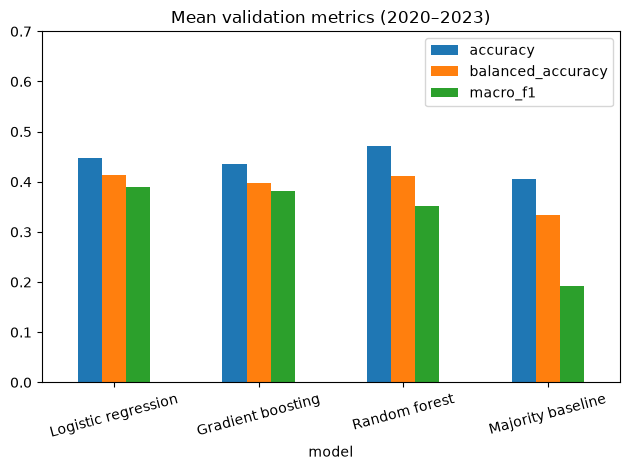

Selected: Logistic regression | 2024 holdout: {'accuracy': 0.5032679738562091, 'balanced_accuracy': 0.43346741622053025, 'macro_f1': 0.41681341082959716}
Holdout majority baseline: {'accuracy': 0.4673202614379085, 'balanced_accuracy': 0.3333333333333333, 'macro_f1': 0.21232368225686712}


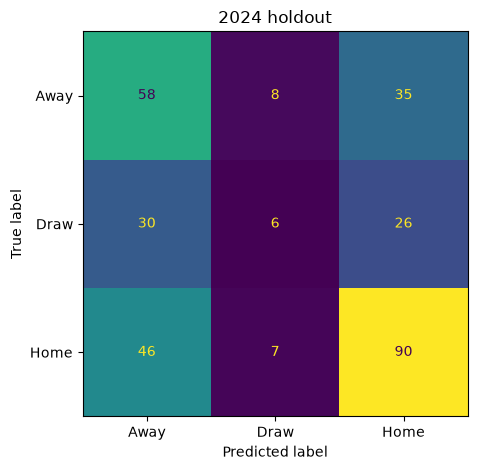

In [20]:
comparison.plot.bar(rot=15,ylim=(0,0.7),title='Mean validation metrics (2020–2023)'); plt.tight_layout(); plt.show()
best_name=comparison.index[0]
tr=features[features.season<2024]; hold=features[features.season==2024]
held_model=clone(models[best_name]).fit(tr[cols],tr.results)
pred=held_model.predict(hold[cols])
holdout=scores(hold.results,pred)
print('Selected:',best_name, '| 2024 holdout:',holdout)
print('Holdout majority baseline:',scores(hold.results,clone(models['Majority baseline']).fit(tr[cols],tr.results).predict(hold[cols])))
ConfusionMatrixDisplay.from_predictions(hold.results,pred,labels=[-1,0,1],display_labels=['Away','Draw','Home'],colorbar=False); plt.title('2024 holdout'); plt.tight_layout(); plt.show()

## 4. Final prediction
Refit on all labeled seasons. Join predictions by game ID to preserve the exact submission order. The supplied target labels are unavailable: the CSV is not evidence of target-season accuracy.

In [21]:
final_model=clone(models[best_name]).fit(features[cols],features.results)
forecast=pd.DataFrame({'game_id':target.game_id,'results':final_model.predict(target[cols]).astype(int)})
submission=sample[['game_id']].merge(forecast,on='game_id',how='left',validate='1:1')
assert list(submission.columns)==list(sample.columns)
assert submission.game_id.equals(sample.game_id)
assert submission.results.notna().all() and set(submission.results).issubset({-1,0,1})
Path('results').mkdir(exist_ok=True)
submission.to_csv('results/submission.csv',index=False)
cv.to_csv('results/validation_scores.csv',index=False)
pd.DataFrame([{'model':best_name,**holdout}]).to_csv('results/holdout_scores.csv',index=False)
submission.head()

,game_id,results
0,4635006,-1
1,4635007,-1
2,4635008,-1
3,4635009,0
4,4635010,-1


## 5. Limitations and next steps
- Football is uncertain; accuracy alone is insufficient, particularly for draws.
- Fixed preseason features cannot reflect injuries, transfers or form changes during the target season.
- Promoted clubs can have sparse or stale top-flight history. Missing values are handled by the models, not fabricated.
- Historical valuations and lineup-based proxies could improve the experiment only after verifying dates, club membership and availability.
- A separate rolling matchday evaluation would be appropriate if updated results were available in deployment.
- The source archive is supplied for coursework; redistribution rights have not been established.